In [213]:
%load_ext autoreload
%autoreload 2
import time
from time import perf_counter
import scipy
import matplotlib.pyplot as plt
import numpy as np
from helpers import *
from srrqr_algo5_final import srrqr_algo5
from randomized_srrqr import randomized_srrqr
from randomized_qdp import *
np.set_printoptions(linewidth=200)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
M_kahan = np.loadtxt('M_kahan.csv', delimiter=',')
M_devils = np.loadtxt('M_devils.csv', delimiter=',')
M_stewart = np.loadtxt('M_stewart.csv', delimiter=',')
matrices = [M_kahan, M_devils, M_stewart]
matrices_name = ['kahan', 'devils', 'stewart']

In [6]:
# Examples of call of functions
# -----------------------------
# SRRQR
# R, P, k = srrqr_algo5(M_kahan, f=2, tol=1e-10, k_stop=1, type_of_algo='tol')

# Randomized SRRQR
# Q, R, P_sk, k, (time_sketching, time_algo, time_qr) = randomized_srrqr(M, M_sk=None, mixed=False, f=2, tol=1e-7, k_stop=None, type_of_algo='tol')

# Low-Rank Approximation
# Q, D_l, P, M_hat_l = randomized_qdp(M_devils, rank_l=30, load=True, name='devils', f=2, tol=1e-7, k_stop=None, type_of_algo='tol')

## Runtime Comparison

Running the algorithm on the regular matrices 

In [22]:
runtime = {}
for i, M in enumerate(matrices):  
    runtime_matrix = []
    print(f"Computing runtime for {matrices_name[i]} matrix:")
    for _ in range(10):
        start_time = time.time()
        R, P, k, tau_k = srrqr_algo5(M, f=2, tol=1e-6, type_of_algo='tol')
        end_time = time.time()
        taken_time = end_time - start_time
        print("--- %s seconds ---" % (taken_time))
        runtime_matrix.append(taken_time)
    print(50*"-")
    runtime[matrices_name[i]] = runtime_matrix

Computing runtime for kahan matrix:
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.500492334365845 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.518083572387695 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.457971096038818 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.508785963058472 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.514533996582031 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.490106582641602 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.4522669315338135 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.490889072418213 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.49117112159729 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 5.552275180816

##### Running the randomized algorithm

In [23]:
runtime_randomized = {}

for i, M in enumerate(matrices):
    runtime_randomized_matrix = {'Sketch': [], 'Algo': [], 'QR': []}
    print(f"Computing runtime for {matrices_name[i]} matrix with randomized algorithm:")
    
    for _ in range(10):
        start_time = time.time()
        Q, R, P_sk, k, runtimes = randomized_srrqr(M, M_sk=None, mixed=False, f=2, tol=1e-6, k_stop=None, type_of_algo='tol')
        end_time = time.time()
        
        taken_time = end_time - start_time
        print("--- %s seconds ---" % (taken_time))
        
        # Append the runtimes to the corresponding lists
        runtime_randomized_matrix['Sketch'].append(runtimes[0])
        runtime_randomized_matrix['Algo'].append(runtimes[1])
        runtime_randomized_matrix['QR'].append(runtimes[2])
    
    print(50 * "-")
    runtime_randomized[matrices_name[i]] = runtime_randomized_matrix

Computing runtime for kahan matrix with randomized algorithm:
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.561007499694824 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.878407716751099 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 13.592395305633545 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.661088228225708 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.638181924819946 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.466404438018799 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.983752489089966 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.785174369812012 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 12.882212400436401 seconds ---
Gamma max is smaller than the tolerance: stoppi

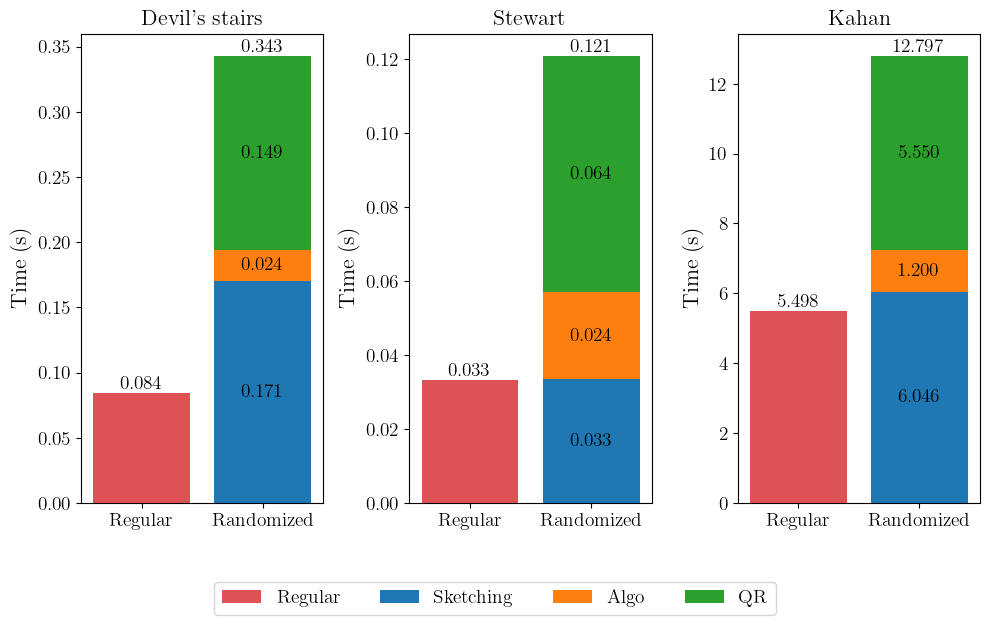

In [371]:
fig = plot_runtime_comparison_by_parts(runtime['devils'], runtime_randomized['devils'], runtime['stewart'], runtime_randomized['stewart'], 
                               runtime['kahan'], runtime_randomized['kahan'])
fig.savefig('time_comparison_reg_rand_by_parts.png', bbox_inches='tight')

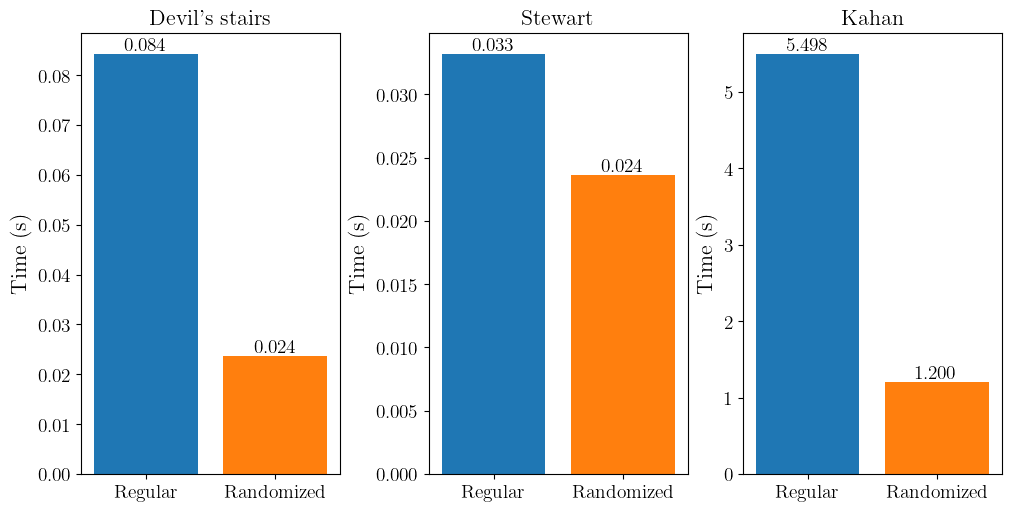

In [317]:
fig = plot_runtime_comparison(runtime['devils'], runtime_randomized['devils']['Algo'], runtime['stewart'], runtime_randomized['stewart']['Algo'], 
                              runtime['kahan'], runtime_randomized['kahan']['Algo'])
fig.savefig('time_comparison_reg_rand_only_algo.png')

## Ratios Computation

In [290]:
ratios_MA = {}
ratios_CM = {}

for i, M in enumerate(matrices):  
    print(f"Computing ratios for {matrices_name[i]} matrix...")
    # Run regular and randomized algorithm
    R, _, k, tau_k = srrqr_algo5(M, f=2, tol=1e-6, k_stop=399, type_of_algo='tol')
    _, R_rand, _, k_rand, _, tau_k_rand = randomized_srrqr(M, M_sk=None, mixed=False, f=2, tol=1e-6, k_stop=None, type_of_algo='tol')

    print("k", k)
    print("k_rand", k_rand)
    print("tau_k", tau_k)
    print("tau_k_rand", tau_k_rand)
    
    # Get A and C
    A = R[:k, :k]
    B = R[:k, k:]
    C = R[k:, k:]
    
    A_rand = R_rand[:k_rand, :k_rand]
    B_rand = R_rand[:k_rand, k_rand:]
    C_rand = R_rand[k_rand:, k_rand:]

    print("Max A^-1B", np.max(np.linalg.inv(A)@B))
    print("Max A^-1B rand", np.max(np.linalg.inv(A_rand)@B_rand))

    # Compute ratios
    ratio_MA, ratio_CM = compute_ratios(A, C, M, k)
    ratio_MA_rand, ratio_CM_rand = compute_ratios(A_rand, C_rand, M, k_rand)

    ratios_MA[matrices_name[i]] = {"MA_regular": ratio_MA, "MA_randomized": ratio_MA_rand}
    ratios_CM[matrices_name[i]] = {"CM_regular": ratio_CM, "CM_randomized": ratio_CM_rand}

    print("Max MA ratios", np.max(ratio_MA))
    print("Max CM ratios", np.max(ratio_CM))
    
    print("Max MA rand ratios", np.max(ratio_MA_rand))
    print("Max CM rand ratios", np.max(ratio_CM_rand))
    print("Done ----------------------")

Computing ratios for kahan matrix...


C:\Users\Corentin\Desktop\EPFL\Master\Master3\Semester_project\StrongRRQR\implementation.py:65: RuntimeWarning: invalid value encountered in sqrt
  # Update gamma


Gamma max is smaller than the tolerance: stopping the algorithm
Gamma max is smaller than the tolerance: stopping the algorithm
k 201
k_rand 200
tau_k 3
tau_k_rand 2
Max A^-1B 0.36234595306292916
Max A^-1B rand 0.5187887792528216
Max MA ratios 1.4308046459279784
Max CM ratios 13.826182191447238
Max MA rand ratios 15.73370298287732
Max CM rand ratios 1673.526950686226
Done ----------------------
Computing ratios for devils matrix...
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k 99
k_rand 99
tau_k 0
tau_k_rand 0
Max A^-1B 0.5875417758240408
Max A^-1B rand 0.49540403825350054
Max MA ratios 1.1466228898263844
Max CM ratios 2.82813488342532
Max MA rand ratios 1.219726405087215
Max CM rand ratios 2.851397856995023
Done ----------------------
Computing ratios for stewart matrix...
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k 99
k_rand 99
tau_k 0
tau_k_rand 0
Max A^-1B 0.1931549640913095
Max A^-1B rand 0.186397268

In [294]:
eps = 0.25
a = np.sqrt((1+eps)/(1-eps))
a

np.float64(1.2909944487358056)

In [298]:
(99*(100-99)*4*a+1)**0.5

np.float64(22.63258274478145)

In [296]:
np.sqrt(2)*2

np.float64(3.6514837167011076)

In [287]:
# Kahan
ratios_MA_kahan = ratios_MA['kahan']["MA_regular"]
ratios_CM_kahan = ratios_CM['kahan']["CM_regular"]
ratios_MA_kahan_randomized = ratios_MA['kahan']["MA_randomized"]
ratios_CM_kahan_randomized = ratios_CM['kahan']["CM_randomized"]

# Stewart
ratios_MA_stewart = ratios_MA['stewart']["MA_regular"]
ratios_CM_stewart = ratios_CM['stewart']["CM_regular"]
ratios_MA_stewart_randomized = ratios_MA['stewart']["MA_randomized"]
ratios_CM_stewart_randomized = ratios_CM['stewart']["CM_randomized"]

# Devil's
ratios_MA_devils = ratios_MA['devils']["MA_regular"]
ratios_CM_devils = ratios_CM['devils']["CM_regular"]
ratios_MA_devils_randomized = ratios_MA['devils']["MA_randomized"]
ratios_CM_devils_randomized = ratios_CM['devils']["CM_randomized"]

In [288]:
ratios_CM_stewart, ratios_CM_stewart_randomized, ratios_CM_devils, ratios_CM_devils_randomized #, ratios_CM_kahan, ratios_CM_kahan_randomized

(array([1.53195402]),
 array([1.5527899]),
 array([2.82813488]),
 array([2.85139786]))

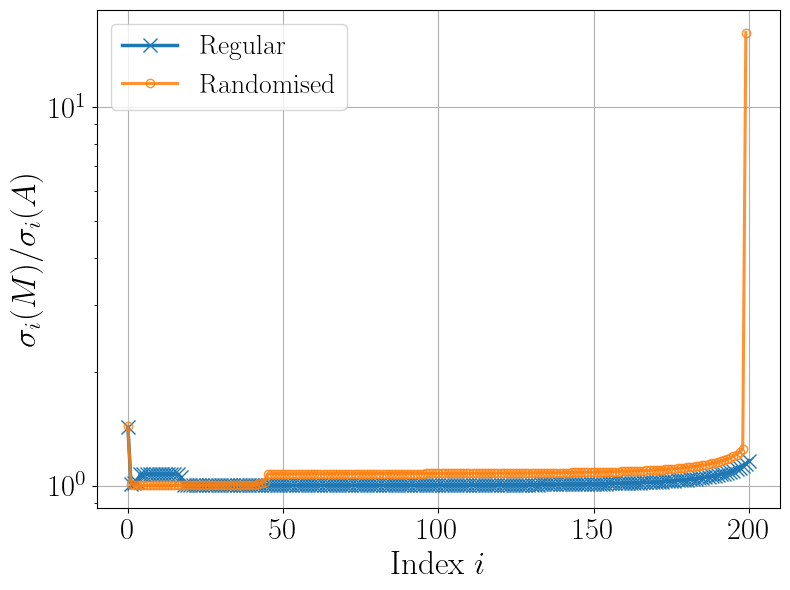

In [289]:
fig = plot_ratios(ratios_MA_kahan, ratios_MA_kahan_randomized)
fig.savefig('ratios_MA_kahan.png')

In [254]:
ratios_CM_kahan[-1]

np.float64(3.3792156639101376e-27)

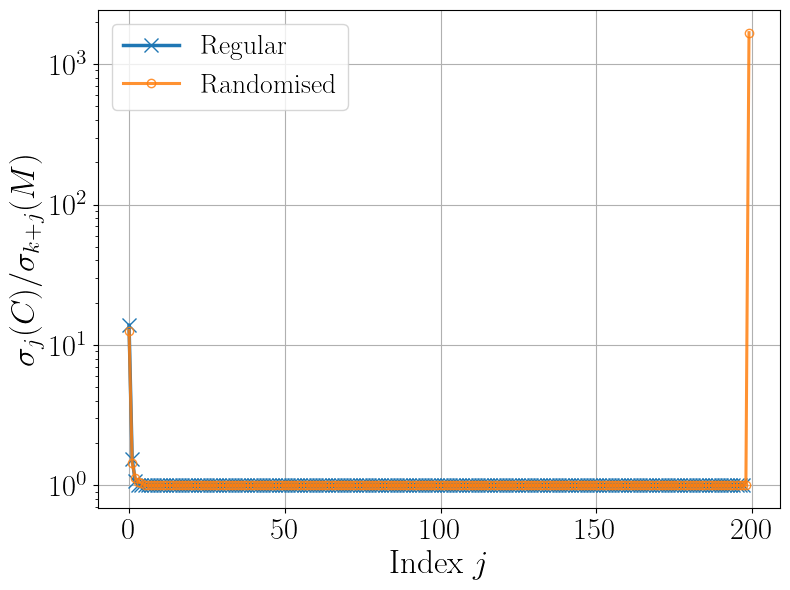

In [255]:
fig = plot_ratios(ratios_CM_kahan[:-1], ratios_CM_kahan_randomized, MA=False)
fig.savefig('ratios_CM_kahan.png')

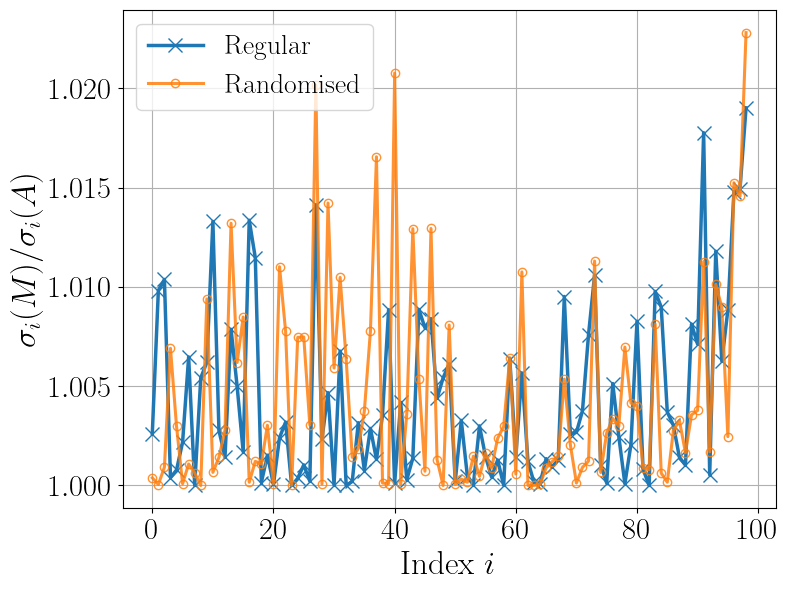

In [256]:
fig = plot_ratios(ratios_MA_stewart, ratios_MA_stewart_randomized, name='Stewart')
fig.savefig('ratios_MA_stewart.png')

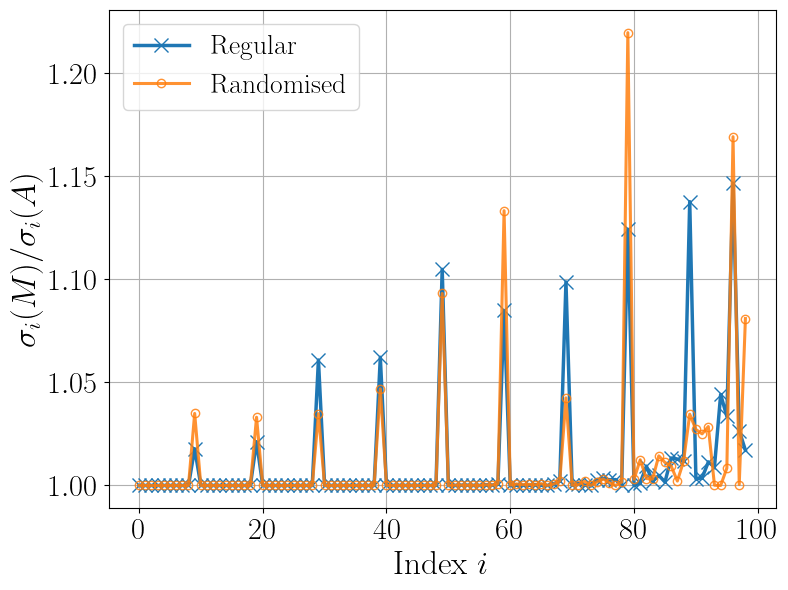

In [257]:
fig = plot_ratios(ratios_MA_devils, ratios_MA_devils_randomized, name="Devil's stairs")
fig.savefig('ratios_MA_devils.png')

#### Singular values of M and M_sk

Kahan

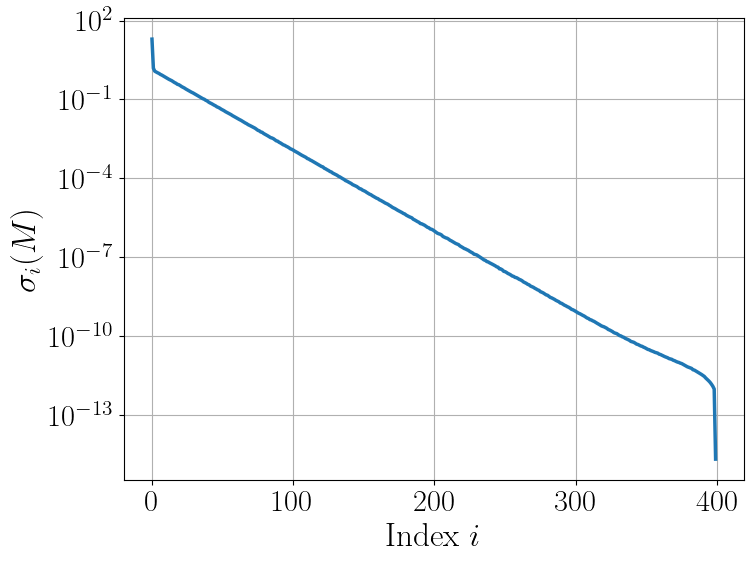

In [266]:
fig = plot_singular_values(M_kahan, 'Kahan')
fig.savefig('singular_values_kahan.png')

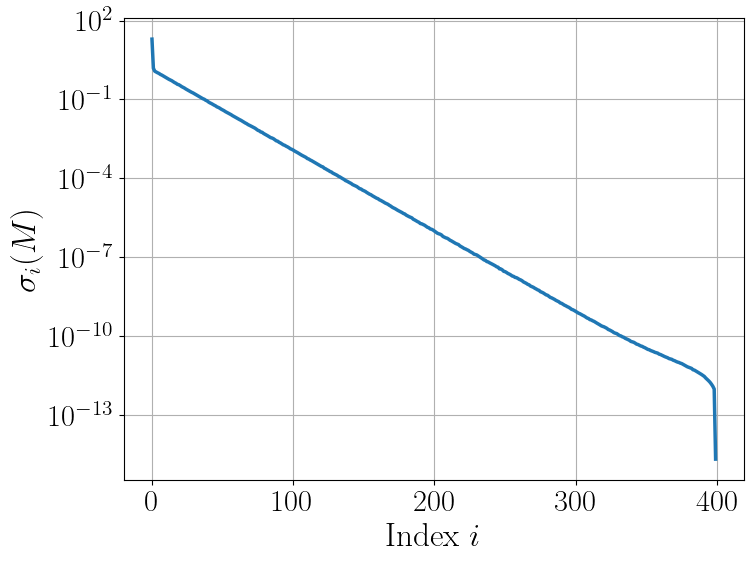

In [268]:
fig = plot_singular_values(M_kahan, sketched=True)
fig.savefig('singular_values_kahan_sketched.png')

Stewart

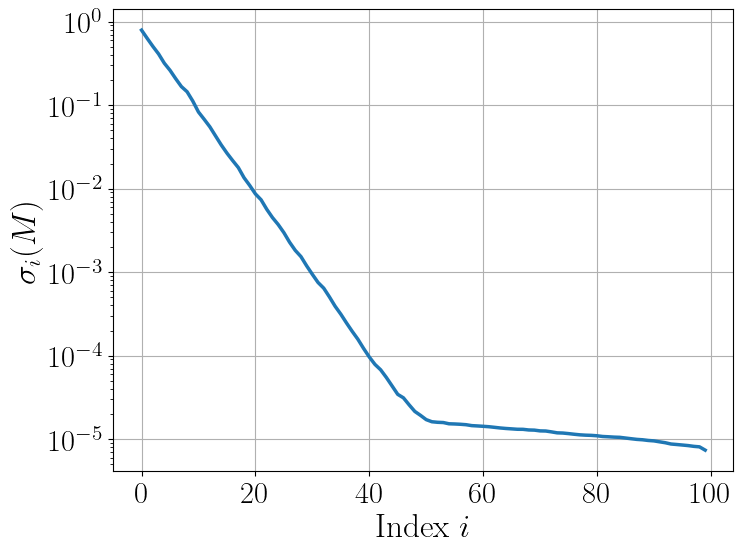

In [269]:
fig = plot_singular_values(M_stewart, 'Stewart')
fig.savefig('singular_values_stewart.png')

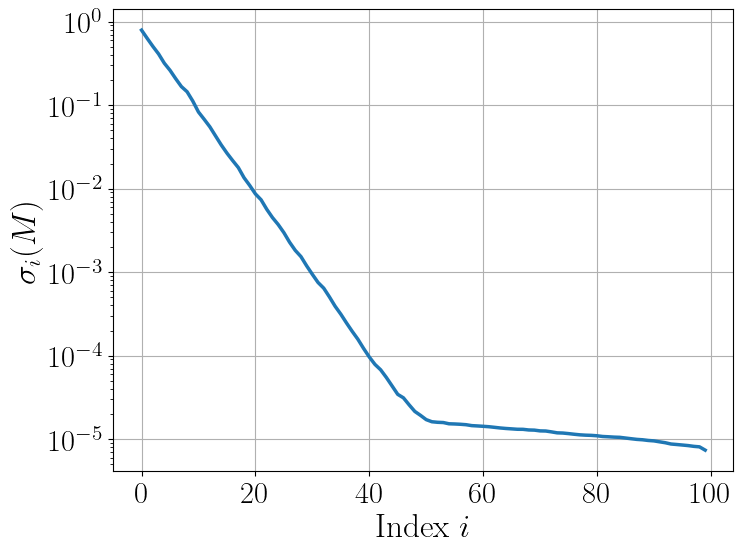

In [270]:
fig = plot_singular_values(M_stewart, sketched=True)
fig.savefig('singular_values_stewart_sketched.png')

Devil's stairs

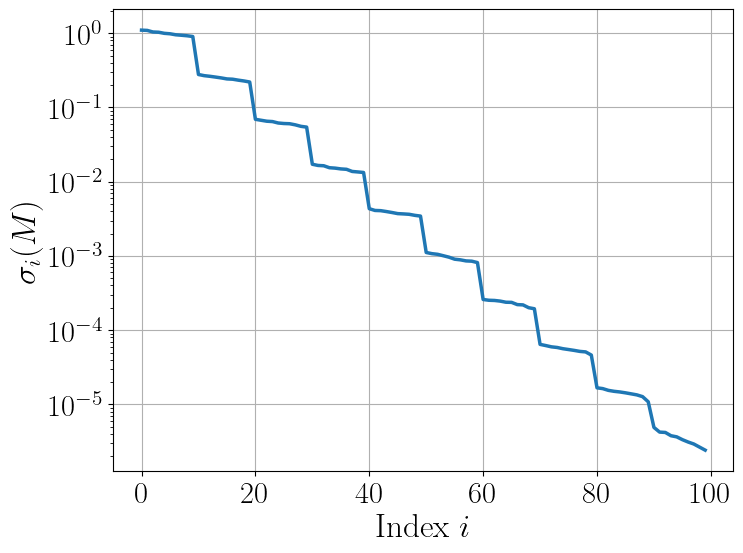

In [271]:
fig = plot_singular_values(M_devils, 'Devils')
fig.savefig('singular_values_devils.png')

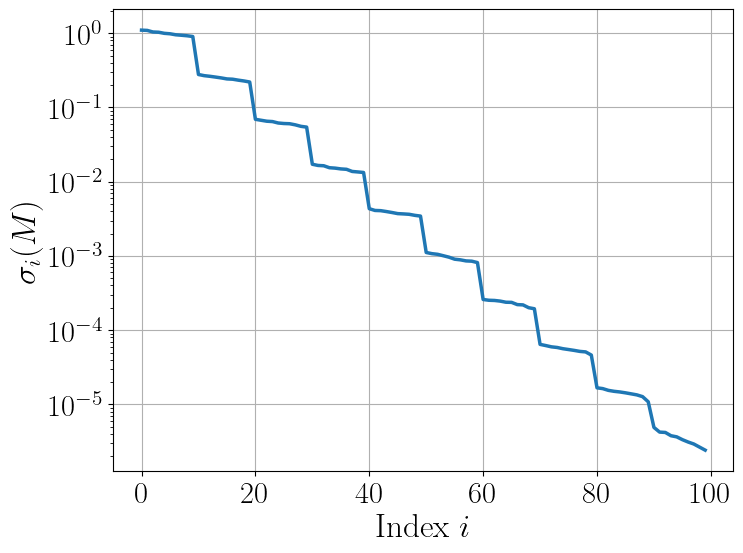

In [272]:
fig = plot_singular_values(M_devils, sketched=True)
fig.savefig('singular_values_devils_sketched.png')

## Mixed-Precision

In [355]:
runtime_randomized_mixed = {}

for i, M in enumerate(matrices):
    runtime_randomized_mixed_matrix = {'Sketch': [], 'Algo': [], 'QR': []}
    print(f"Computing runtime for {matrices_name[i]} matrix with randomized algorithm:")
    
    for _ in range(10):
        start_time = time.time()
        Q, R, P_sk, k, runtimes = randomized_srrqr(M, M_sk=None, mixed=True, f=2, tol=1e-6, k_stop=None, type_of_algo='tol')
        end_time = time.time()
        
        taken_time = end_time - start_time
        print("--- %s seconds ---" % (taken_time))
        
        # Append the runtimes to the corresponding lists
        runtime_randomized_mixed_matrix['Sketch'].append(runtimes[0])
        runtime_randomized_mixed_matrix['Algo'].append(runtimes[1])
        runtime_randomized_mixed_matrix['QR'].append(runtimes[2])
    
    print(50 * "-")
    runtime_randomized_mixed[matrices_name[i]] = runtime_randomized_mixed_matrix

Computing runtime for kahan matrix with randomized algorithm:


C:\Users\Corentin\Desktop\EPFL\Master\Master3\Semester_project\StrongRRQR\implementation.py:41: RuntimeWarning: invalid value encountered in sqrt
  gamma[:-1] = np.sqrt(gamma[1:] ** 2 - c_T ** 2)


Gamma max is smaller than the tolerance: stopping the algorithm
--- 7.474754333496094 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 8.4587242603302 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 7.78369140625 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 8.127478837966919 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 8.134258031845093 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 7.9525275230407715 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 7.5516791343688965 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 7.86246657371521 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 7.431537628173828 seconds ---
Gamma max is smaller than the tolerance: stopping the algorithm
--- 7.039500713348389 seconds ---
-------------------------

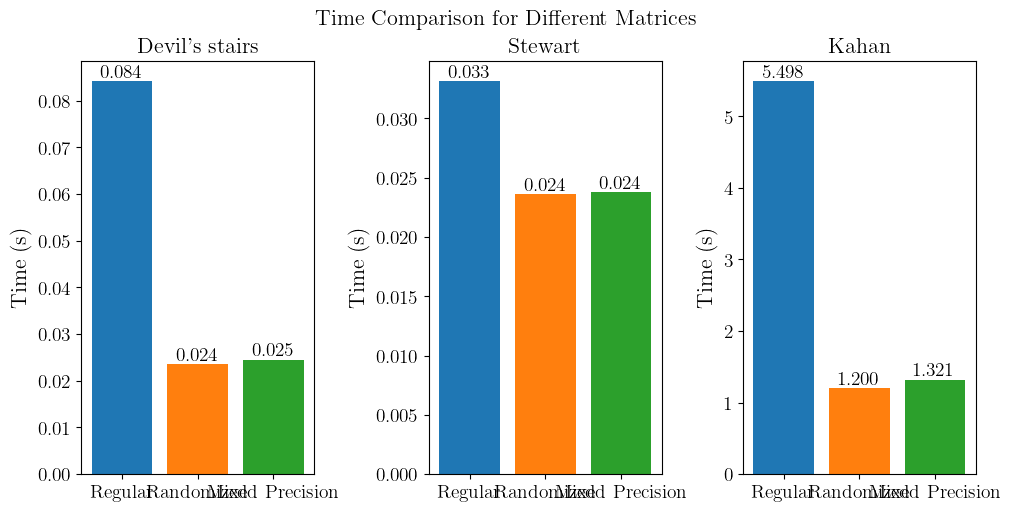

In [356]:
"""
fig = plot_runtime_comparison_with_mixed(runtime['devils'], runtime_randomized['devils']['Algo'], runtime_randomized_mixed['devils']['Algo'],
                                         runtime['stewart'], runtime_randomized['stewart']['Algo'], runtime_randomized_mixed['stewart']['Algo'],
                                         runtime['kahan'], runtime_randomized['kahan']['Algo'], runtime_randomized_mixed['kahan']['Algo'])
fig.savefig('time_comparison_reg_rand_mixed_only_algo.png')
"""

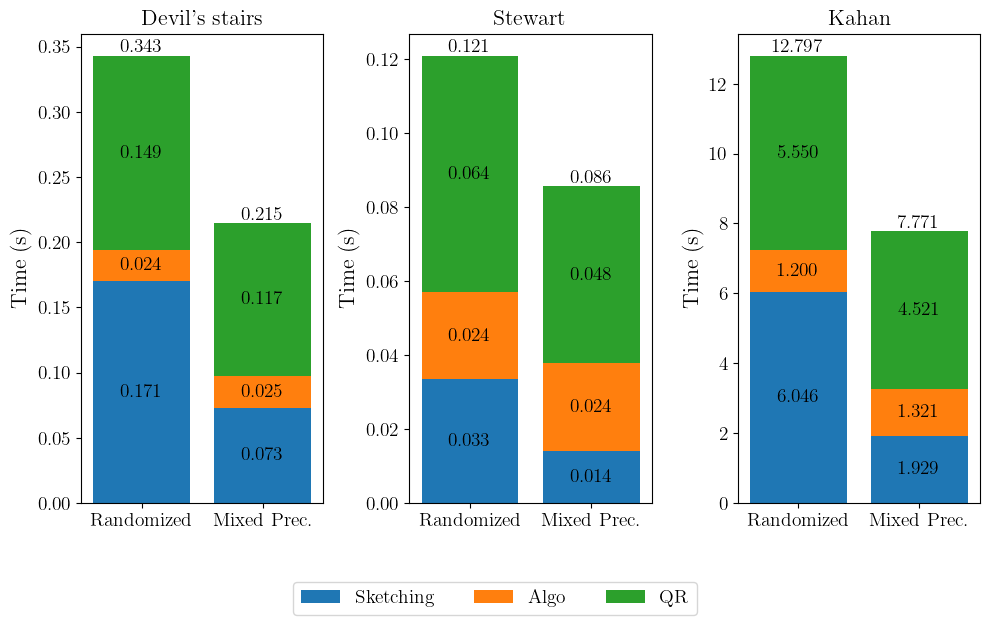

In [359]:
fig = plot_runtime_comparison_with_mixed_parts(runtime_randomized['devils'], runtime_randomized_mixed['devils'],
                               runtime_randomized['stewart'], runtime_randomized_mixed['stewart'],
                               runtime_randomized['kahan'], runtime_randomized_mixed['kahan'])
fig.savefig('time_comparison_rand_mixed_by_parts.png', bbox_inches='tight')

In [123]:
ratios_mixed = {}

for i, M in enumerate(matrices):  
    print(f"Computing ratios for {matrices_name[i]} matrix...")
    # Run regular and randomized algorithm
    _, R_rand, _, k_rand, _, tau_k_mixed = randomized_srrqr(M, M_sk=None, mixed=True, f=2, tol=1e-6, k_stop=None, type_of_algo='tol')

    print("tau_k_mixed", tau_k_mixed)
    
    A_rand = R_rand[:k_rand, :k_rand]
    B_rand = R_rand[:k_rand, k_rand:]
    C_rand = R_rand[k_rand:, k_rand:]

    print("Max A^-1B mixed", np.max(np.linalg.inv(A_rand)@B_rand))

    # Compute ratios
    ratio_MA_rand, ratio_CM_rand = compute_ratios(A_rand, C_rand, M, k_rand)

    ratios_mixed[matrices_name[i]] = {"MA": ratio_MA_rand, "CM": ratio_CM_rand}
       
    print("Max MA mixed ratios", np.max(ratio_MA_rand))
    print("Max CM mixed ratios", np.max(ratio_CM_rand))
    print("Done ----------------------\n")

Computing ratios for kahan matrix...
Gamma max is smaller than the tolerance: stopping the algorithm
tau_k_mixed 4
Max A^-1B mixed 0.5187888
Max MA mixed ratios 15.256127105016942
Max CM mixed ratios 81400969361.6904
Done ----------------------

Computing ratios for devils matrix...
k is equal to n-1: stopping the algorithm
tau_k_mixed 0
Max A^-1B mixed 0.49503028
Max MA mixed ratios 1.2197661226783425
Max CM mixed ratios 2.8537054541677183
Done ----------------------

Computing ratios for stewart matrix...
k is equal to n-1: stopping the algorithm
tau_k_mixed 0
Max A^-1B mixed 0.18637334
Max MA mixed ratios 1.0227024163866896
Max CM mixed ratios 1.5527539825690029
Done ----------------------



In [104]:
ratio_MA_mixed_kahan = ratios_mixed['kahan']['MA']
ratio_CM_mixed_kahan = ratios_mixed['kahan']['CM']

ratio_MA_mixed_stewart = ratios_mixed['stewart']['MA']
ratio_CM_mixed_stewart = ratios_mixed['stewart']['CM']

ratio_MA_mixed_devils = ratios_mixed['devils']['MA']
ratio_CM_mixed_devils = ratios_mixed['devils']['CM']

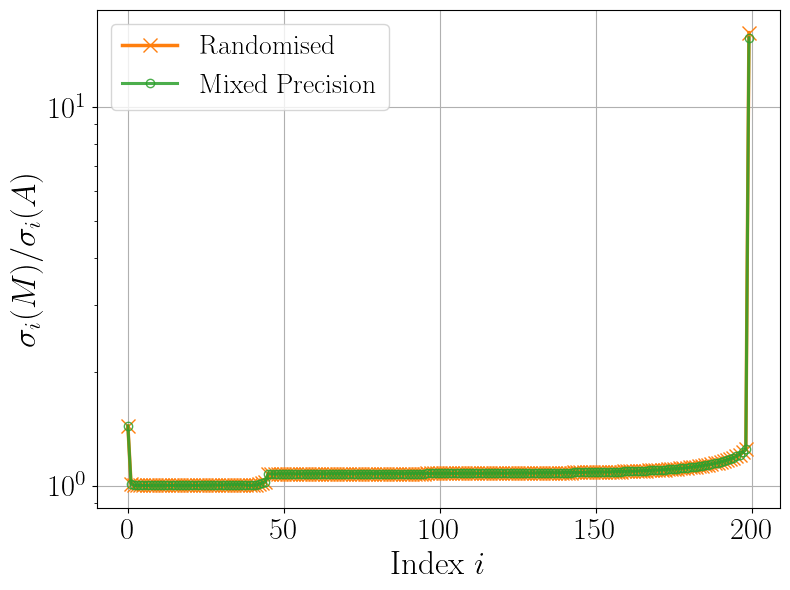

In [258]:
fig = plot_ratios(ratios_MA_kahan_randomized, ratio_MA_mixed_kahan, mixed=True)
fig.savefig('ratios_MA_kahan_mixed.png')

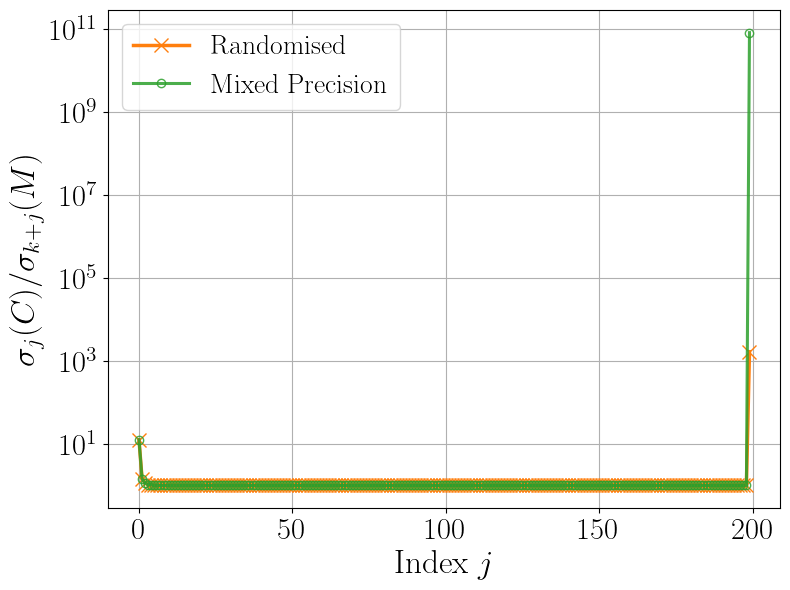

In [259]:
fig = plot_ratios(ratios_CM_kahan_randomized, ratio_CM_mixed_kahan, MA=False, mixed=True)
fig.savefig('ratios_CM_kahan_mixed.png')

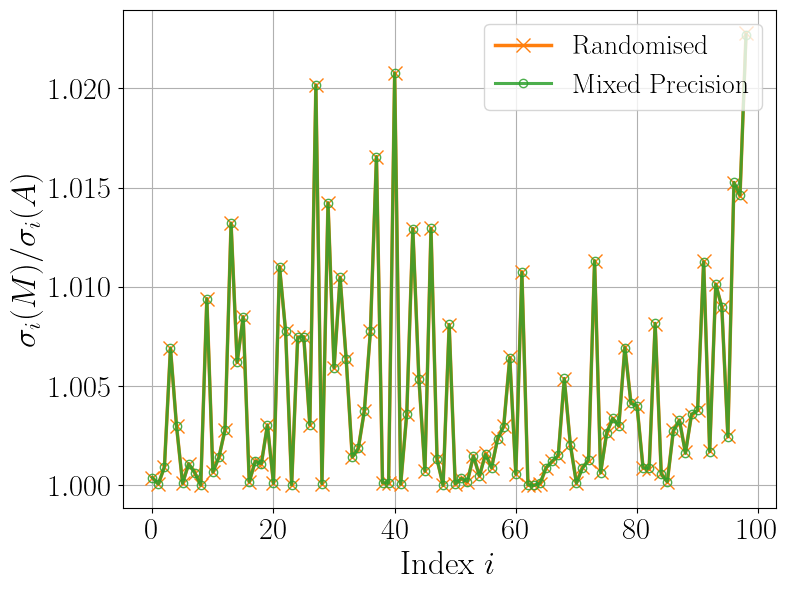

In [263]:
fig = plot_ratios(ratios_MA_stewart_randomized, ratio_MA_mixed_stewart, name='Stewart', mixed=True)
fig.savefig('ratios_MA_stewart_mixed.png')

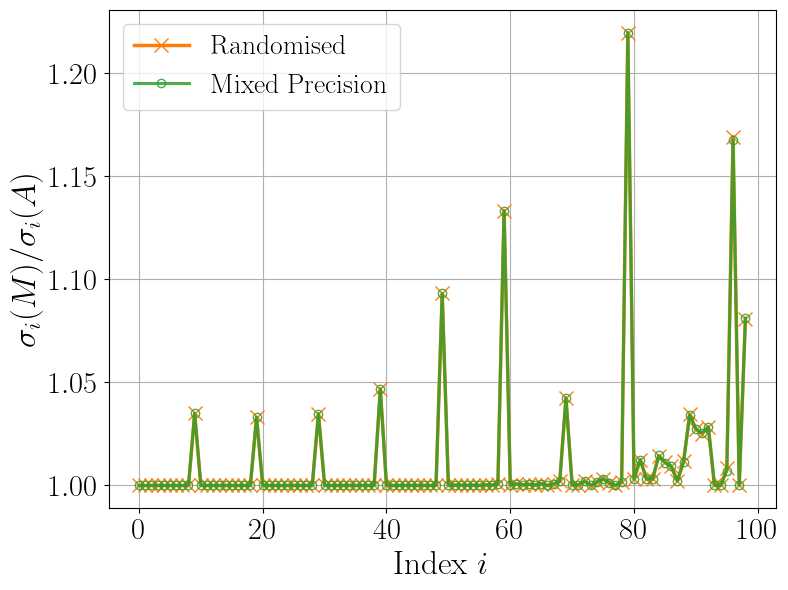

In [262]:
fig = plot_ratios(ratios_MA_devils_randomized, ratio_MA_mixed_devils, name="Devil's stairs", mixed=True)
fig.savefig('ratios_MA_devils_mixed.png')

## Comparison with Scipy QR

In [248]:
runtime_scipy = {}
for i, M in enumerate(matrices):  
    runtime_scipy_matrix = []
    print(f"Computing runtime for {matrices_name[i]} matrix:")
    for _ in range(10):
        start_time = time.time()
        Q, R, P = scipy.linalg.qr(M, pivoting=True)
        end_time = time.time()
        taken_time = end_time - start_time
        print("--- %s seconds ---" % (taken_time))
        runtime_scipy_matrix.append(taken_time)
    print(50*"-")
    runtime_scipy[matrices_name[i]] = runtime_scipy_matrix

Computing runtime for kahan matrix:
--- 5.142392158508301 seconds ---
--- 5.776627063751221 seconds ---
--- 5.671878814697266 seconds ---
--- 5.748607397079468 seconds ---
--- 5.773770332336426 seconds ---
--- 6.045579671859741 seconds ---
--- 5.748323917388916 seconds ---
--- 5.427074432373047 seconds ---
--- 5.363144397735596 seconds ---
--- 5.457424640655518 seconds ---
--------------------------------------------------
Computing runtime for devils matrix:
--- 0.19753170013427734 seconds ---
--- 0.1845865249633789 seconds ---
--- 0.15058088302612305 seconds ---
--- 0.14551568031311035 seconds ---
--- 0.1609818935394287 seconds ---
--- 0.14424657821655273 seconds ---
--- 0.15352463722229004 seconds ---
--- 0.1482992172241211 seconds ---
--- 0.15967822074890137 seconds ---
--- 0.1649034023284912 seconds ---
--------------------------------------------------
Computing runtime for stewart matrix:
--- 0.08015108108520508 seconds ---
--- 0.04505586624145508 seconds ---
--- 0.0595495700836

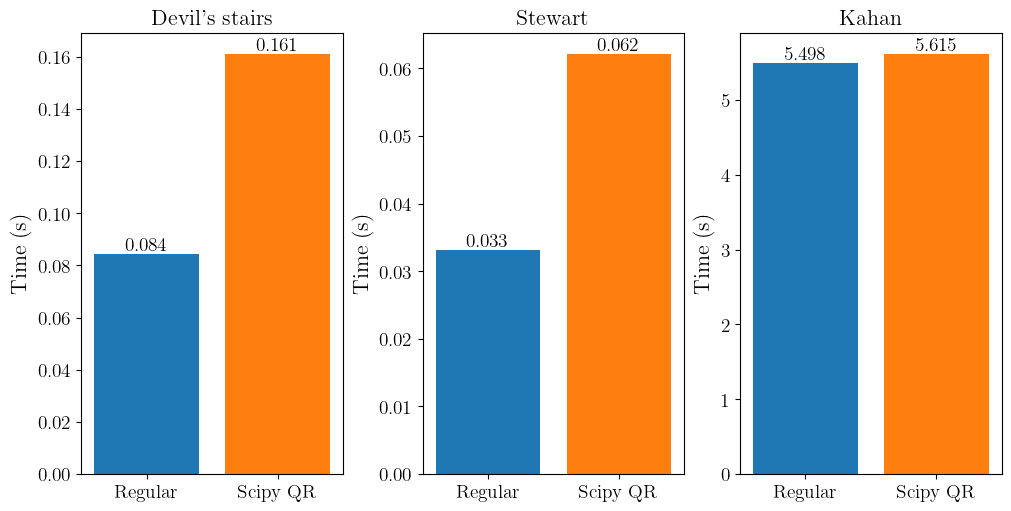

In [323]:
fig = plot_runtime_comparison(runtime['devils'], runtime_scipy['devils'], 
                              runtime['stewart'], runtime_scipy['stewart'],
                              runtime['kahan'], runtime_scipy['kahan'], scipy_comparison=True)

fig.savefig('time_comparison_reg_scipy_only_algo.png')

## Low-rank approximation

Compute the theoretical bound

In [143]:
array_of_l = np.arange(1, 61)

In [145]:
_, S_M_devils, _ = np.linalg.svd(M_devils)
_, S_M_stewart, _ = np.linalg.svd(M_stewart)

In [146]:
bounds_devils = []
bounds_stewart = []

for l in array_of_l:
    bounds_devils.append(compute_theoretical_bound(k=99, n=M_devils.shape[1], f=2, eps=0.25, sigma_l_plus_1=S_M_devils[l]))
    bounds_stewart.append(compute_theoretical_bound(k=99, n=M_stewart.shape[1], f=2, eps=0.25, sigma_l_plus_1=S_M_stewart[l]))

Compute the low-rank approximation

In [147]:
M = M_stewart.copy()
svd_error_stewart, error_stewart = low_rank_approximation(M, array_of_l, 'stewart')

k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the al

In [148]:
M = M_devils.copy()
svd_error_devils, error_devils = low_rank_approximation(M, array_of_l, 'devils')

k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the algorithm
k is equal to n-1: stopping the al

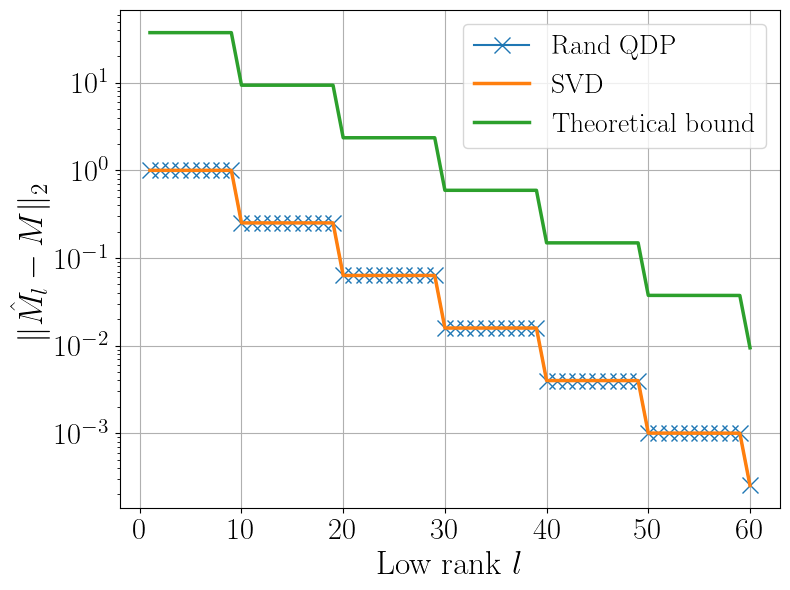

In [264]:
fig = plot_low_rank_approximation(svd_error_devils, error_devils, array_of_l, bounds_devils)
fig.savefig('low_rank_devils.png')

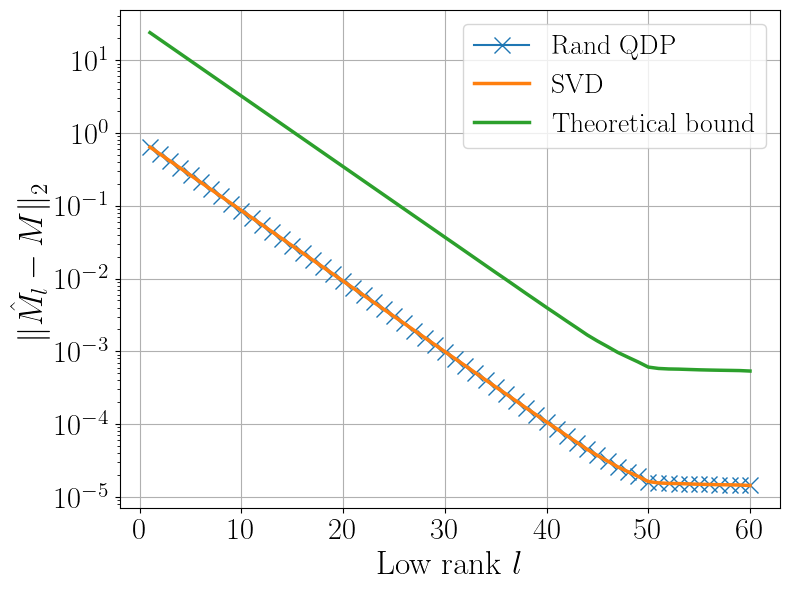

In [265]:
fig = plot_low_rank_approximation(svd_error_stewart, error_stewart, array_of_l, bounds_stewart)
fig.savefig('low_rank_stewart.png')